In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


In [32]:
x=np.linspace(-0.5,0.5,100)
y=np.sqrt(10**2 -x**2)
y=np.hstack([y,-y])
x=np.hstack([x,-x])

In [34]:
y

array([ 9.98749218,  9.98799274,  9.98848306,  9.98896315,  9.98943299,
        9.98989261,  9.99034198,  9.99078113,  9.99121004,  9.99162873,
        9.99203718,  9.99243541,  9.99282341,  9.99320119,  9.99356874,
        9.99392607,  9.99427318,  9.99461007,  9.99493673,  9.99525318,
        9.99555942,  9.99585543,  9.99614123,  9.99641682,  9.99668219,
        9.99693734,  9.99718229,  9.99741702,  9.99764154,  9.99785586,
        9.99805996,  9.99825385,  9.99843754,  9.99861101,  9.99877428,
        9.99892735,  9.9990702 ,  9.99920286,  9.9993253 ,  9.99943754,
        9.99953958,  9.99963141,  9.99971304,  9.99978446,  9.99984568,
        9.99989669,  9.99993751,  9.99996812,  9.99998852,  9.99999872,
        9.99999872,  9.99998852,  9.99996812,  9.99993751,  9.99989669,
        9.99984568,  9.99978446,  9.99971304,  9.99963141,  9.99953958,
        9.99943754,  9.9993253 ,  9.99920286,  9.9990702 ,  9.99892735,
        9.99877428,  9.99861101,  9.99843754,  9.99825385,  9.99

In [35]:
x1 = np.linspace(-0.5,0.5,100)
y1 = np.sqrt(10**2 -x1**2)
y1=np.hstack([y1,-y1])
x1=np.hstack([x1,-x1])

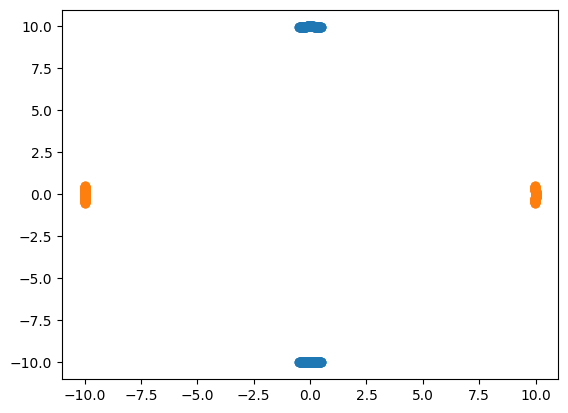

In [40]:
plt.scatter(x,y)
plt.scatter(y1,x1)

In [42]:
import pandas as pd
df1=pd.DataFrame(np.vstack([y,x]).T,columns=['x1','x2'])
df1['Y']=0
df2=pd.DataFrame(np.vstack([y1,x1]).T,columns=['x1','x2'])
df2['Y']=1
df = pd.concat([df1, df2])
df.head(5)

,x1,x2,Y
0,9.987492,-0.500000,0
1,9.987993,-0.489899,0
2,9.988483,-0.479798,0
3,9.988963,-0.469697,0
4,9.989433,-0.459596,0


In [43]:
df.tail()

,x1,x2,Y
195,-9.989433,-0.459596,1
196,-9.988963,-0.469697,1
197,-9.988483,-0.479798,1
198,-9.987993,-0.489899,1
199,-9.987492,-0.500000,1


In [44]:
X=df.iloc[:,:2]
y=df.Y

In [45]:
y

,Y
0,0
1,0
2,0
3,0
4,0
...,...
195,1
196,1
197,1
198,1


In [46]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [47]:
y_train

,Y
3,0
18,0
2,1
50,1
74,1
...,...
71,0
106,0
70,1
148,1


# POLYNOMIAL KERNEL

In [49]:
df['X1_square']=df['x1']**2
df['X2_square']=df['x2']**2
df['X1_X2']=df['x1']*df['x2']
df.head()

,x1,x2,Y,X1_square,X2_square,X1_X2
0,9.987492,-0.500000,0,99.750000,0.250000,-4.993746
1,9.987993,-0.489899,0,99.759999,0.240001,-4.893108
2,9.988483,-0.479798,0,99.769794,0.230206,-4.792454
3,9.988963,-0.469697,0,99.779385,0.220615,-4.691786
4,9.989433,-0.459596,0,99.788772,0.211228,-4.591103


In [51]:
X= df[['x1','x2','X1_square','X1_X2']]
y=df['Y']

In [52]:
y

,Y
0,0
1,0
2,0
3,0
4,0
...,...
195,1
196,1
197,1
198,1


In [53]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=0)

In [54]:
X_train

,x1,x2,X1_square,X1_X2
136,-9.999070,0.136364,99.981405,-1.363510
64,9.998927,0.146465,99.978548,1.464489
55,9.999846,0.055556,99.996914,0.555547
106,-9.990342,0.439394,99.806933,-4.389696
100,-9.987492,0.500000,99.750000,-4.993746
...,...,...,...,...
123,-9.996417,0.267677,99.928349,-2.675809
192,-9.990781,-0.429293,99.815708,4.288972
117,-9.994610,0.328283,99.892230,-3.281059
47,9.999968,-0.025253,99.999362,-0.252524


In [55]:
import plotly.express as px
fig=px.scatter_3d(df,x='x1',y='x2',z='Y',color='Y')
fig.show()

In [56]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

classifier = SVC(kernel='poly')
y_pred=classifier.fit(X_train,y_train).predict(X_test)
accuracy_score(y_test,y_pred)

0.425

In [59]:
classifier = SVC(kernel='rbf')
y_pred=classifier.fit(X_train,y_train).predict(X_test)
accuracy_score(y_test,y_pred)

0.425

In [2]:
from sklearn.datasets import make_classification

In [29]:
X,y=make_classification(n_samples=1000,n_features=3,n_classes=2,n_clusters_per_class=1, n_informative=1)

In [16]:
X

array([[-0.86300058,  0.76654015, -0.48199042],
       [-0.18972728,  0.16852084, -0.1059637 ],
       [-1.28313244,  1.13971249, -0.71663631],
       ...,
       [ 0.99163313, -0.88079501,  0.55383239],
       [ 1.00574627, -0.89333069,  0.56171466],
       [-1.92276583,  1.70785194, -1.07387497]])

In [17]:
y

array([0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0,
       0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0,
       1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1,
       0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1,
       1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1,
       1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1,

<Axes: xlabel='0', ylabel='1'>

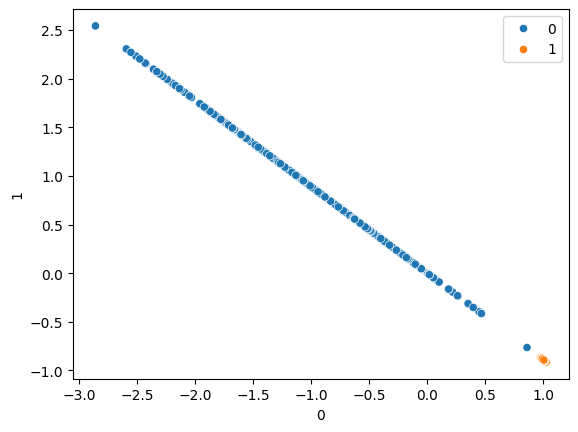

In [18]:
sns.scatterplot(x=pd.DataFrame(X)[0],y=pd.DataFrame(X)[1],hue=y)

In [19]:
from sklearn.svm import SVC

In [20]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [30]:
svc =SVC(kernel='linear') # HERE THE DATASET IS EASY TO CLASSIFY BUT THE WHENEVER WE HAVE DIFFICULT DATASET, THEN WE CHANGE THE KERNAL , AFTER THE KERNAL APPLIED THE TRANSFORMATION HAS BEEN APPLIED DIFFERENTLY , WHICH CAN INCREAE THE ACCURACY.

In [22]:
svc.fit(X_train,y_train)

SVC(kernel='linear')

In [23]:
y_pred = svc.predict(X_test)

In [26]:
from sklearn.metrics import accuracy_score, classification_report

In [27]:
print(classification_report(y_test,y_pred))
print(accuracy_score(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99        95
           1       0.99      0.99      0.99       105

    accuracy                           0.99       200
   macro avg       0.99      0.99      0.99       200
weighted avg       0.99      0.99      0.99       200

0.99


In [31]:
# ALSO WE CAN INCREAE THE ACCURAACY WITH HYPER PARAMETER TUNING AND WHICH ALSO GOING TO HELP US TO INCREASE THE ACCURACY